# From-scratch Q-learning on Taxi-v3
Topics in AI, Assignment I. See `FA26-TAI-AI.pdf` for requirements. This notebook executes a fresh training run, shows its progress, then inspects the full three-seed learning-rate study. Run `python main.py all` first to regenerate that study.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
from IPython.display import display, Image
from agent import Config, QLearningAgent
from utils import train, evaluate
print("Python:", sys.executable)
assert sys.prefix != sys.base_prefix, "Run this notebook inside the project virtual environment"

Python: C:\Users\user\OneDrive\Desktop\topics in ai assignmnet\.venv\Scripts\python.exe


## Environment and algorithm
500 encoded states and six actions. Q-learning uses $Q(s,a) \leftarrow Q(s,a)+\alpha[r+\gamma(1-\mathrm{terminated})\max_b Q(s_{next},b)-Q(s,a)]$. Truncation ends a rollout but retains bootstrapping. All actions are available; no action mask is used.

In [2]:
config = Config(alpha=0.5, episodes=12000)
agent, history, checkpoints = train(config, seed=0)
print("Episode | greedy validation return | success")
for episode, mean_return, success in checkpoints:
    print(f"{episode:7.0f} | {mean_return:24.2f} | {success:7.1%}")

Episode | greedy validation return | success
   1000 |                     3.44 |   98.0%
   2000 |                     7.54 |  100.0%
   3000 |                     7.54 |  100.0%
   4000 |                     7.54 |  100.0%
   5000 |                     7.54 |  100.0%
   6000 |                     7.54 |  100.0%
   7000 |                     7.54 |  100.0%
   8000 |                     7.54 |  100.0%
   9000 |                     7.54 |  100.0%
  10000 |                     7.54 |  100.0%
  11000 |                     7.54 |  100.0%
  12000 |                     7.54 |  100.0%


In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(200, len(history)+1), np.convolve(history[:,1], np.ones(200)/200, "valid"))
ax.set(xlabel="Episode", ylabel="200-episode mean return", title="Fresh seed-0 training run")
display(fig)
plt.close(fig)

<Figure size 900x300 with 1 Axes>

## Independent evaluation
The test reset seeds differ from training and validation seeds. The random baseline receives the same test reset seeds and the same time limit.

In [4]:
print("Fresh trained policy:", evaluate(agent.q))
print("Uniform random:", evaluate())

Fresh trained policy: {'mean_return': 7.994, 'std_return': 2.546755583089983, 'mean_steps': 13.006, 'success_rate': 1.0, 'mean_illegal': 0.0, 'episodes': 500}


Uniform random: {'mean_return': -773.024, 'std_return': 90.44825826957643, 'mean_steps': 197.618, 'success_rate': 0.042, 'mean_illegal': 64.032, 'episodes': 500}


## Learning-rate sensitivity across three training seeds
The complete experiment compares alpha 0.1, 0.5, and 0.9 with seeds 0, 1, and 2. Curves show mean and one standard deviation of smoothed training returns. Validation selects the learning rate; test results are reported after selection.

Selected configuration: {'alpha': 0.1, 'seed': 0, 'criterion': 'Highest mean validation return across three seeds; ties choose lower alpha. Deployment uses predeclared seed 0.'}
0.1 test mean return: 8.03 success: 1.0
0.5 test mean return: 7.989999999999999 success: 1.0
0.9 test mean return: 8.019333333333334 success: 1.0


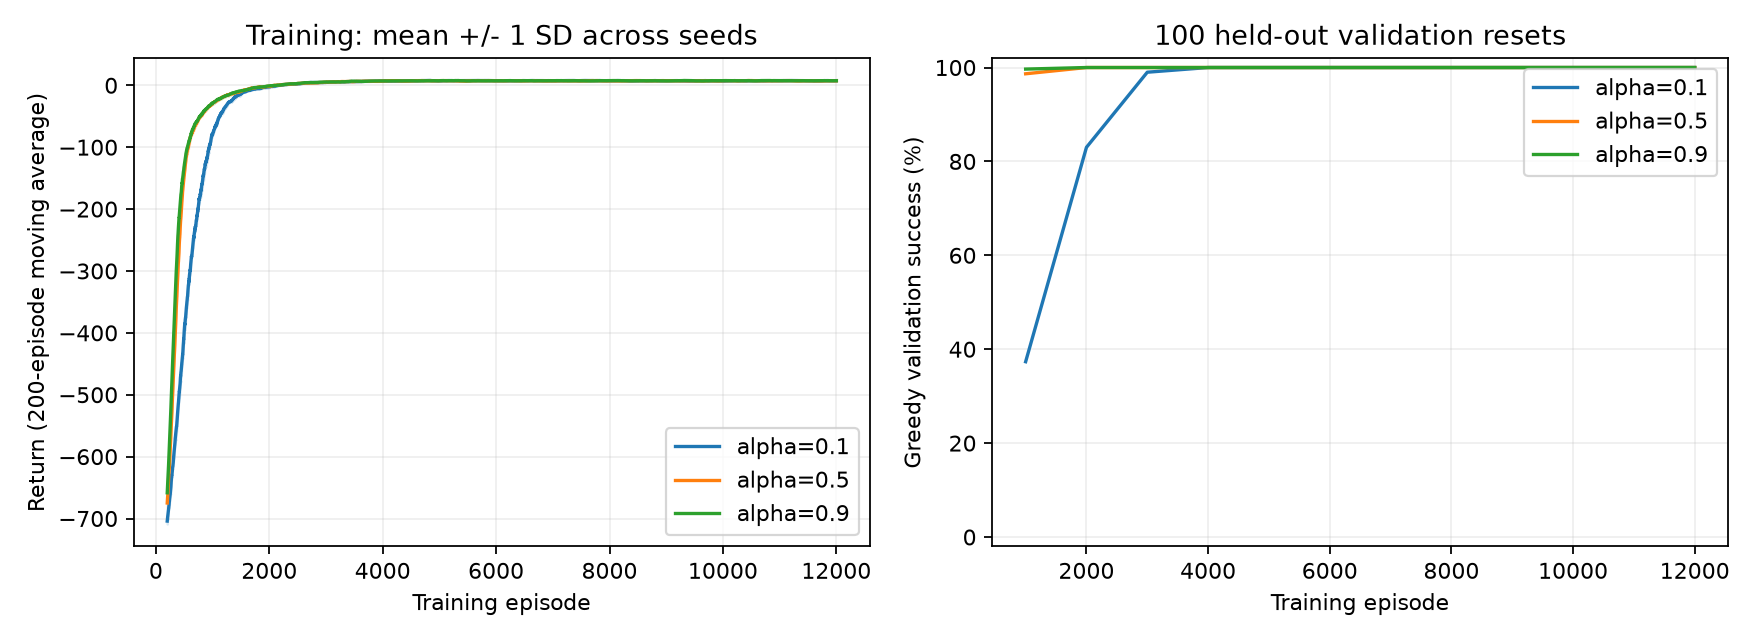

In [5]:
results = json.loads(Path("artifacts/results.json").read_text())
print("Selected configuration:", results["selection"])
for alpha in ("0.1", "0.5", "0.9"):
    scores = results["test"][alpha]
    print(alpha, "test mean return:", np.mean([s["mean_return"] for s in scores]), "success:", np.mean([s["success_rate"] for s in scores]))
display(Image(filename="artifacts/learning_curves.png"))

## Saved model and successful demonstration

Saved table: (500, 6)


Selected policy test: {'mean_return': 8.03, 'std_return': 2.552861139976086, 'mean_steps': 12.97, 'success_rate': 1.0, 'mean_illegal': 0.0, 'episodes': 500}
Demonstration: {'seed': 40000, 'steps': 10, 'total_return': 11, 'success': True}


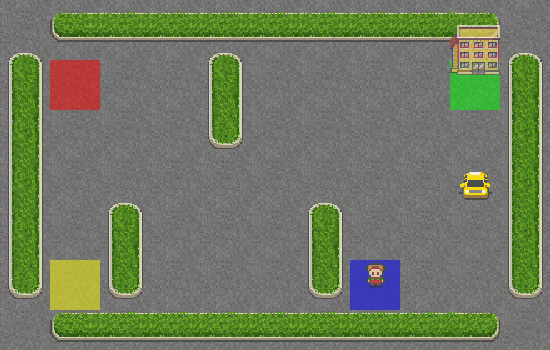

In [6]:
saved = QLearningAgent(500, 6)
saved.load("artifacts/q_table.npy")
print("Saved table:", saved.q.shape)
print("Selected policy test:", evaluate(saved.q))
print("Demonstration:", results["demo"])
display(Image(filename="artifacts/taxi_policy.gif"))

## Discussion
Compare early validation checkpoints as well as final returns: settings can reach the same final performance at different speeds. Training returns include exploration penalties, while greedy evaluation measures the learned policy. Three seeds and 500 sampled test resets provide empirical evidence, not a convergence proof or exhaustive guarantee. The report discusses failure modes and scope. All measured results and episode logs are in `artifacts/`.